# Supplementary Fig. 7c: ratio of sorted to true neuron count by firing rate

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel c of Supplementary Fig. 7: ratio of the sorted divided by the true neuron count in each logarithmic firing rate bin (one line for each layer).

**data**: the first 10 minutes of the Kilosort4 sorting (single-units) and of the ground truth of the spontaneous Neuropixels simulation (`dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m`, `dataset/00_raw/ground_truth_npx_spont`). Run time: about 10 seconds.

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.validation import true_firing_rate_plots as t

# SETUP PLOT
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 400}
OUT = "figures/8_source_data/supp_fig7c"
os.makedirs(OUT, exist_ok=True)

## Source data

In [2]:
df = t.get_count_ratio(t.get_firing_rates())

In [3]:
display(df.head(8))

layer,L1,L2/3,L4,L5,L6
log firing rate,,,,,
-2.933333,NaN,1.780339e-47,8.714076e-55,2.877751e-51,4.600472e-52
-2.800000,NaN,1.287082e-42,1.731179e-49,3.689521e-46,5.717577e-47
-2.666667,NaN,7.543129e-38,2.914471e-44,3.668337e-41,5.326088e-42
-2.533333,NaN,2.382802e-33,2.983122e-39,1.821324e-36,2.625005e-37
-2.400000,2.508922e-41,3.148364e-29,1.324439e-34,3.853112e-32,6.618460e-33
-2.266667,1.978052e-36,2.038543e-25,2.384758e-30,4.456930e-28,9.404004e-29
-2.133333,5.372961e-32,6.852320e-22,1.838191e-26,2.968754e-24,6.725169e-25
-2.000000,7.002660e-28,1.168387e-18,7.745151e-23,1.003764e-20,2.216594e-21


## Plot

In [4]:
def plot_source_data(df):
    """Panel c; the axes have the size of the paper's panel"""
    ax_w, ax_h = t.PANEL_SIZE["c"]
    left, bottom, top, right = 0.6, 0.5, 0.35, 0.1   # inches
    fig = plt.figure(figsize=(left + ax_w + right, bottom + ax_h + top))
    ax = fig.add_axes([left / fig.get_figwidth(), bottom / fig.get_figheight(), ax_w / fig.get_figwidth(), ax_h / fig.get_figheight()])
    t.plot_count_ratio(ax, df)
    return fig

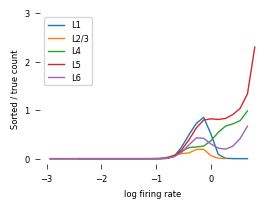

In [5]:
fig = plot_source_data(df)

In [6]:
plt.savefig(f"{OUT}/supp_fig7c.svg", bbox_inches="tight", **savefig_cfg)

<Figure size 640x480 with 0 Axes>

## Save source data

In [7]:
df_save = df.reset_index() if df.index.name else df
df_save.to_excel(f"{OUT}/supp_fig7c.xlsx", sheet_name="count_ratio", index=False)

## Replot from the saved source data (the xlsx is sufficient to reproduce the panel)

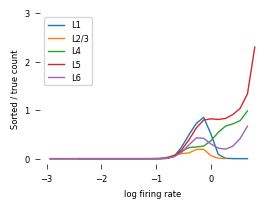

In [8]:
df = pd.read_excel(f"{OUT}/supp_fig7c.xlsx", index_col=0)
fig = plot_source_data(df)